In [13]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service as ChromeService
from webdriver_manager.chrome import ChromeDriverManager
import time

# Set up the Chrome WebDriver
options = webdriver.ChromeOptions()
options.add_argument('--headless')  # Run headlessly
options.add_argument('--disable-gpu')  # Disable GPU acceleration
options.add_argument('--no-sandbox')  # Bypass OS security model
options.add_argument('--disable-dev-shm-usage')  # Overcome limited resource problems

driver = webdriver.Chrome(service=ChromeService(ChromeDriverManager().install()), options=options)

# Open the YouTube video page
url = 'https://www.youtube.com/watch?v=jQ1l5zenaKY'
driver.get(url)

In [14]:
elements = driver.find_elements(By.CLASS_NAME, 'ytp-heat-map-path')


In [15]:
elements

[<selenium.webdriver.remote.webelement.WebElement (session="2d8acfc430f3952fc6f3a4b5dd71dd0b", element="f.684139ABBEAE5A11D226C55856E7D9DB.d.BBAB06C1FFD0D4875D5504E1889E32F1.e.33")>,
 <selenium.webdriver.remote.webelement.WebElement (session="2d8acfc430f3952fc6f3a4b5dd71dd0b", element="f.684139ABBEAE5A11D226C55856E7D9DB.d.BBAB06C1FFD0D4875D5504E1889E32F1.e.34")>,
 <selenium.webdriver.remote.webelement.WebElement (session="2d8acfc430f3952fc6f3a4b5dd71dd0b", element="f.684139ABBEAE5A11D226C55856E7D9DB.d.BBAB06C1FFD0D4875D5504E1889E32F1.e.35")>,
 <selenium.webdriver.remote.webelement.WebElement (session="2d8acfc430f3952fc6f3a4b5dd71dd0b", element="f.684139ABBEAE5A11D226C55856E7D9DB.d.BBAB06C1FFD0D4875D5504E1889E32F1.e.36")>,
 <selenium.webdriver.remote.webelement.WebElement (session="2d8acfc430f3952fc6f3a4b5dd71dd0b", element="f.684139ABBEAE5A11D226C55856E7D9DB.d.BBAB06C1FFD0D4875D5504E1889E32F1.e.37")>,
 <selenium.webdriver.remote.webelement.WebElement (session="2d8acfc430f3952fc6f3a4b5d

In [16]:
heat_map_values = [element.get_attribute('d') for element in elements]


In [30]:
heat_map_values[1].split('C')

['M 0.0,100.0 ',
 ' 0.0,97.0 -33.3,88.1 0.0,85.2 ',
 ' 33.3,82.2 66.7,88.9 166.7,85.2 ',
 ' 266.7,81.4 366.7,65.5 500.0,66.5 ',
 ' 633.3,67.4 733.3,85.1 833.3,89.8 ',
 ' 933.3,94.4 966.7,87.7 1000.0,89.8 ',
 ' 1033.3,91.8 1000.0,98.0 1000.0,100.0']

In [38]:
heat_map_values[0]

'M 0.0,100.0 C 5.3,80.0 10.5,2.0 26.3,0.0 C 42.1,-2.0 57.9,80.5 78.9,90.0 C 100.0,99.5 110.5,50.6 131.6,47.7 C 152.6,44.7 163.2,68.1 184.2,75.4 C 205.3,82.6 215.8,84.1 236.8,84.1 C 257.9,84.1 268.4,74.2 289.5,75.4 C 310.5,76.5 321.1,88.0 342.1,90.0 C 363.2,92.0 373.7,85.5 394.7,85.5 C 415.8,85.5 426.3,94.6 447.4,90.0 C 468.4,85.4 478.9,63.1 500.0,62.4 C 521.1,61.7 531.6,83.0 552.6,86.6 C 573.7,90.2 584.2,81.0 605.3,80.5 C 626.3,80.0 636.8,82.1 657.9,84.0 C 678.9,85.9 689.5,91.9 710.5,90.0 C 731.6,88.1 742.1,76.1 763.2,74.6 C 784.2,73.1 794.7,80.2 815.8,82.7 C 836.8,85.2 847.4,87.0 868.4,86.9 C 889.5,86.9 900.0,82.9 921.1,82.5 C 942.1,82.2 957.9,84.6 973.7,85.2 C 989.5,85.7 994.7,82.2 1000.0,85.2 C 1005.3,88.1 1000.0,97.0 1000.0,100.0'

In [39]:
path_data = heat_map_values[0]

In [64]:
import re

# 예제 SVG 경로 데이터

# SVG 데이터를 파싱하여 y 값을 추출
y_values = re.findall(r'\b[-+]?\d*\.\d+|\d+\b', path_data)
y_values = [float(y_values[i+1]) for i in range(0, len(y_values), 2)]

# heatmap 형식으로 변환
heatmap = y_values

print("heatmap:", heatmap)


heatmap: [100.0, 91.0, 64.0, 55.0, 46.0, 49.9, 55.0, 60.1, 76.0, 80.5, 85.0, 84.7, 77.7, 70.6, 45.9, 45.2, 44.5, 65.2, 74.1, 83.1, 86.8, 90.0, 93.2, 94.9, 90.0, 85.1, 70.3, 65.3, 60.4, 58.4, 65.3, 72.3, 93.1, 100.0]


In [65]:
len(heatmap)

34

In [66]:
import re


# 정규 표현식을 사용하여 C 명령어의 좌표 데이터를 추출
y_all = []
# y값을 추출
for i in range(len(heat_map_values)):
    c_commands = re.findall(r'C [\d\.\-]+,[\d\.\-]+ [\d\.\-]+,[\d\.\-]+ [\d\.\-]+,[\d\.\-]+', heat_map_values[i])
    y_values = []
    for command in c_commands:
        coords = command.split(' ')[1:]  # 첫 번째 요소는 'C'이므로 제외
        for coord in coords:
            _, y = map(float, coord.split(','))
            y_values.append(y)
    y_all.extend(y_values)
    # 결과 출력
    print(len(y_values))

63
18
48
39
54
30
51
33
45
33


In [63]:
len(y_all)

414

In [28]:
for i in range(len(heat_map_values)):
    print(len(heat_map_values[i].split('C')))

22
7
17
14
19
11
18
12
16
12


In [26]:
len(heat_map_values[0].split('C'))

22

In [18]:
len(heat_map_values)

10

In [ ]:
# https://yt.lemnoslife.com/noKey/videos?part=snippet&id=jQ1l5zenaKY

In [8]:
# 동영상 ID
video_id = "mUDFLe3Q__U"

get url!!!
get url finished!!!!!


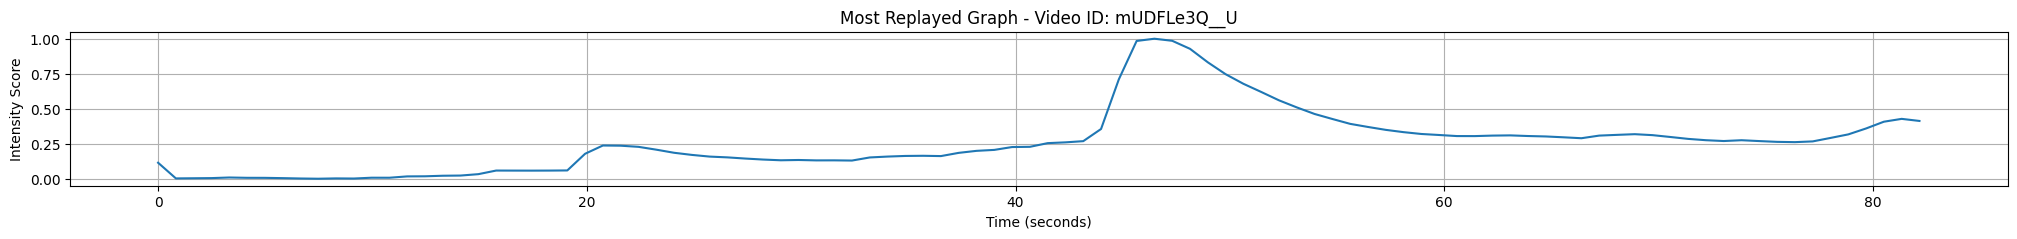

In [9]:



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


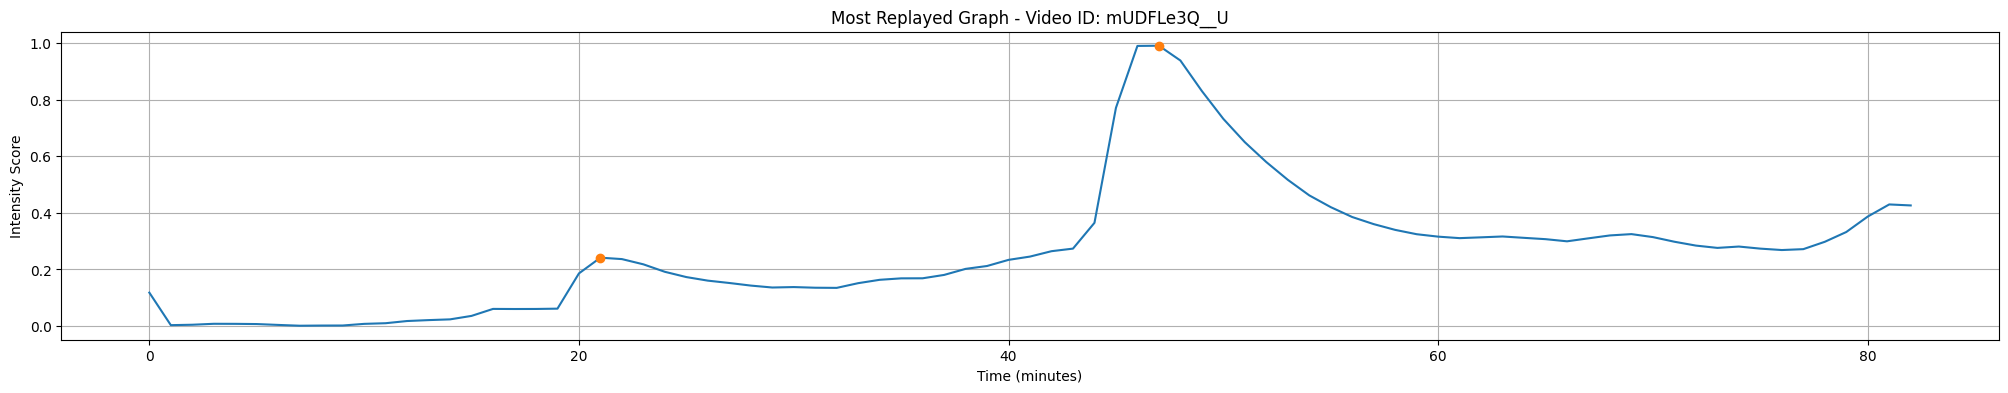

In [ ]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [74]:
rewards_lst = smoothed_intensity_scores

In [75]:
class State:
    def __init__(self, peak_int, count, time, rewards_lst= rewards_lst, ):
        self.peak = peak_int
        self.frame = -1
        self.count = count
        self.time = time
        self.reward = rewards_lst[time]
        self.next_states = []
        self.choose = False

    def get_info(self):
        info = f'Peak: {self.peak}, Count: {self.count}, choose: {self.choose}, Time: {self.time}, Next State {self.next_states}'
        # info = f'Peak: {self.peak}, Count: {self.count},  Next State {self.next_states}'
        return info




In [76]:
# count_durations = []  # 각 피크마다 count_duration을 계산해서 저장

# 각 피크마다 count_duration 계산
# for i, peak in enumerate(peaks):
#     if i < len(peaks) - 1:
#         count_duration = min(50, peaks[i + 1] - peak)
#     else:
#         count_duration = min(50, len(smoothed_intensity_scores) - peak)
#     count_durations.append(count_duration)

In [77]:
states = []
# count_duration = 20 ### 제한 시간
total_length = len(smoothed_intensity_scores)
for i, peak in enumerate(peaks, start=1):
    for j in range(total_length - peak):
        temp = peak + j
        reward = smoothed_intensity_scores[temp]
        time = temp
        state = State(peak_int=i, count=j, time = time )
        states.append(state)

In [78]:
for state in states:
    if state.count == 0:
        state.choose = True

In [79]:
for state in states:
    print(state.get_info())


Peak: 1, Count: 0, choose: True, Time: 21, Next State []
Peak: 1, Count: 1, choose: False, Time: 22, Next State []
Peak: 1, Count: 2, choose: False, Time: 23, Next State []
Peak: 1, Count: 3, choose: False, Time: 24, Next State []
Peak: 1, Count: 4, choose: False, Time: 25, Next State []
Peak: 1, Count: 5, choose: False, Time: 26, Next State []
Peak: 1, Count: 6, choose: False, Time: 27, Next State []
Peak: 1, Count: 7, choose: False, Time: 28, Next State []
Peak: 1, Count: 8, choose: False, Time: 29, Next State []
Peak: 1, Count: 9, choose: False, Time: 30, Next State []
Peak: 1, Count: 10, choose: False, Time: 31, Next State []
Peak: 1, Count: 11, choose: False, Time: 32, Next State []
Peak: 1, Count: 12, choose: False, Time: 33, Next State []
Peak: 1, Count: 13, choose: False, Time: 34, Next State []
Peak: 1, Count: 14, choose: False, Time: 35, Next State []
Peak: 1, Count: 15, choose: False, Time: 36, Next State []
Peak: 1, Count: 16, choose: False, Time: 37, Next State []
Peak: 1,

In [80]:
# 다음 상태 정의 함수
import pdb
def fill_next_states(states, min_duration):
    for state in states:
        next_states = []
        
        for next_state in states:
            
            # 같은 피크 내에서 다음 상태로 전이, 같은 피크 내에서는 1개씩만. 
            if (next_state.peak == state.peak) and (next_state.count == state.count + 1):
                next_states.append(next_state)
                state.choose = True

            # 다음 피크를 선택할 때에는 
            # 진행중인 state가 2초 이상이고,          다음 피트가 현재 피크랑 다르고        피크이고                    현재 지속 시간보다 
            elif  (state.count >= min_duration) and (next_state.peak > state.peak) and (next_state.count == 0) and (state.time < next_state.time):
                next_states.append(next_state)
                state.choose = True
        # print("=======")
        
        if state.choose:
            state.next_states = next_states
        # print(state.next_states)

fill_next_states(states, min_duration=2)


In [81]:
for state in states:
    # print(f"===={state.get_info()}")
    # print(state.next_states)
    for next in state.next_states:
        print(next.get_info())

Peak: 1, Count: 1, choose: True, Time: 22, Next State [<__main__.State object at 0x0000013648034430>]
Peak: 1, Count: 2, choose: True, Time: 23, Next State [<__main__.State object at 0x0000013648036B30>, <__main__.State object at 0x000001364800A680>]
Peak: 1, Count: 3, choose: True, Time: 24, Next State [<__main__.State object at 0x00000136480360B0>, <__main__.State object at 0x000001364800A680>]
Peak: 2, Count: 0, choose: True, Time: 47, Next State [<__main__.State object at 0x000001364800B1F0>]
Peak: 1, Count: 4, choose: True, Time: 25, Next State [<__main__.State object at 0x0000013647FD9BD0>, <__main__.State object at 0x000001364800A680>]
Peak: 2, Count: 0, choose: True, Time: 47, Next State [<__main__.State object at 0x000001364800B1F0>]
Peak: 1, Count: 5, choose: True, Time: 26, Next State [<__main__.State object at 0x0000013647FD8C70>, <__main__.State object at 0x000001364800A680>]
Peak: 2, Count: 0, choose: True, Time: 47, Next State [<__main__.State object at 0x000001364800B1F

In [82]:
def find_highlights(states, temp_states, F):
    dp = np.zeros((len(states), F+1))
    path = [[None for _ in range(F+1)] for _ in range(len(states))]

    for f in range(1, F+1):
        for i, state in enumerate(states):
            for j, temp_state in enumerate(temp_states):
                max_prev_reward = -float('inf')
                best_prev_state = None

    for f in range(1, F+1):
        for i, state in enumerate(states):
            if state.count == 0:
                # print(" here ")
                # print(state.get_info())
                dp[i][f] = state.reward
                path[i][f] = i
            else:
                max_prev_reward = -float('inf')
                best_prev_state = None
                for prev_state in state.next_states:
                    prev_idx = states.index(prev_state)
                    # df [i+1][f]
                    if dp[prev_idx][f-1] + state.reward > max_prev_reward:
                        max_prev_reward = dp[prev_idx][f-1] + state.reward
                        best_prev_state = prev_idx
                if best_prev_state is not None:
                    dp[i][f] = max_prev_reward
                    path[i][f] = best_prev_state

    highlights = []
    highlights_peaks = []
    state_idx = np.argmax(dp[:, -1])
    f = F
    while f > 0 and state_idx is not None:
        highlights.append(states[state_idx].time)
        state_idx = path[state_idx][f]
        print(states[state_idx].peak, states[state_idx].count)
        if states[state_idx].count == 0:
            print("hello")
            highlights_peaks.append(states[state_idx].time)
        f -= 1

    return highlights, highlights_peaks





In [83]:
total_length = 10

In [84]:
highlights, highlights_peaks = find_highlights(states, total_length)


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [ ]:
highlights_peaks

[47, 47, 47, 47, 47, 47, 47, 47, 47, 47]

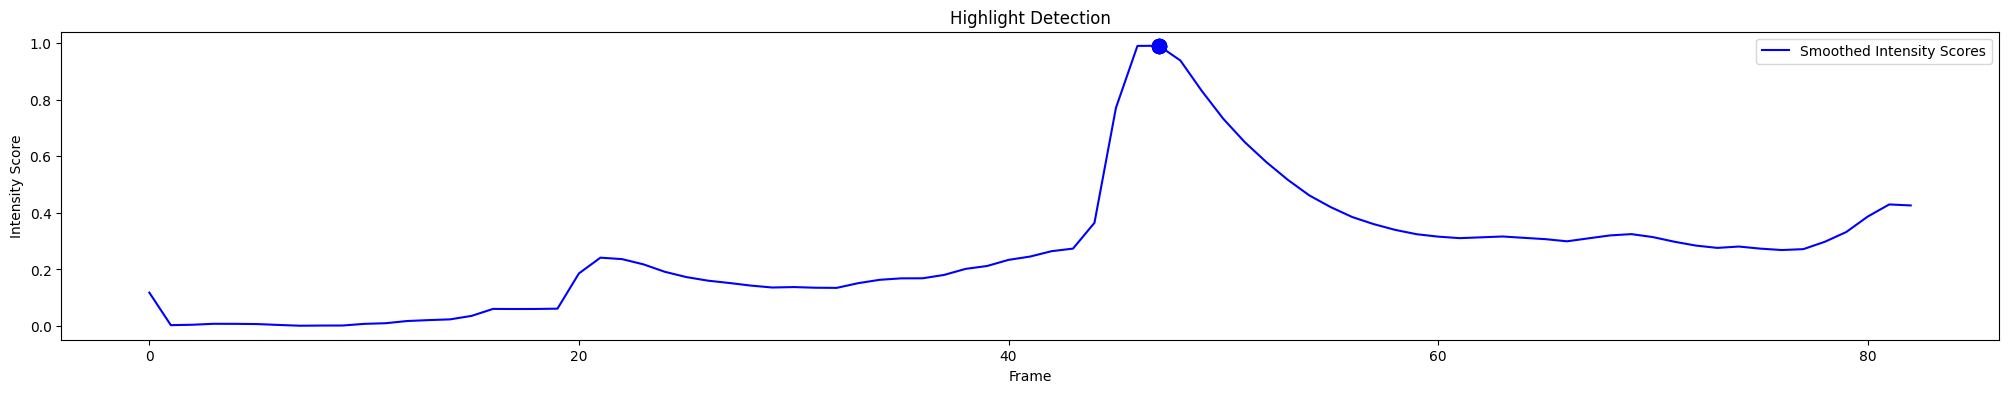

In [ ]:
# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(smoothed_intensity_scores, 'b-', label='Smoothed Intensity Scores')
# 점을 그래프에 표시
for point in highlights:
    plt.scatter(point, smoothed_intensity_scores[point], color='red', s=50)  # s는 점의 크기

for point in highlights_peaks:
    plt.scatter(point, smoothed_intensity_scores[point], color='blue', s=100)  # s는 점의 크기

plt.xlabel('Frame')
plt.ylabel('Intensity Score')
plt.title('Highlight Detection')
plt.legend()
plt.show()

# 앞뒤로 해보기